# Lab Assignment 3 — AI in Healthcare (CSET343)
**Data Acquisition, Cleaning, Preprocessing & Analysis on Tabular, Textual, Image, and Signal Medical Health Data**

This notebook is organized into 4 parts, one per data modality:

| Part | Data Type | Dataset |
|---|---|---|
| A | Tabular | Pima Indians Diabetes Dataset |
| B | Textual | MTSamples Medical Transcriptions |
| C | Image | Chest X-Ray (Pneumonia) |
| D | Signal | MIT-BIH Arrhythmia Database (ECG) |



In [1]:
# ---- Global setup ----
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


---
# Part A — Tabular Data: Pima Indians Diabetes Dataset

Steps: acquisition & inspection → cleaning (implausible clinical values) → EDA → feature engineering/selection → hypothesis test, chi-square test, ANOVA → preprocessing into scaled tensors.


In [3]:
# A.1 Acquisition & inspection
DATA_DIR_A = "diabetes.csv"         
CSV_A = "diabetes.csv"

df_a = pd.read_csv(CSV_A)
print(df_a.shape)
df_a.head()


(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


In [4]:
df_a.info()
print()
print("Missing values (NaN) per column:")
print(df_a.isnull().sum())
print()
print("Descriptive statistics:")
df_a.describe().T


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(4), int64(5)
memory usage: 54.1 KB

Missing values (NaN) per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction  

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,121.677083,30.464161,44.000,99.75000,117.0000,140.25000,199.00
BloodPressure,768.0,72.389323,12.106039,24.000,64.00000,72.0000,80.00000,122.00
SkinThickness,768.0,29.089844,8.890820,7.000,25.00000,28.0000,32.00000,99.00
Insulin,768.0,141.753906,89.100847,14.000,102.50000,102.5000,169.50000,846.00
BMI,768.0,32.434635,6.880498,18.200,27.50000,32.0500,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [5]:
# A.2 Cleaning — implausible clinical values
# In this dataset, 0 is not a physiologically valid value for these columns,
# but is used as a stand-in for "missing" (missingness encoded as a valid-looking value).
zero_invalid_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("Count of implausible zeros per column:")
print((df_a[zero_invalid_cols] == 0).sum())

df_a_clean = df_a.copy()
df_a_clean[zero_invalid_cols] = df_a_clean[zero_invalid_cols].replace(0, np.nan)

print()
print("Missing values after marking implausible zeros as NaN:")
print(df_a_clean.isnull().sum())


Count of implausible zeros per column:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

Missing values after marking implausible zeros as NaN:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [6]:
# A.3 Imputation (median imputation, grouped by Outcome to preserve class signal)
for col in zero_invalid_cols:
    df_a_clean[col] = df_a_clean.groupby("Outcome")[col].transform(lambda s: s.fillna(s.median()))

# Check for any remaining missing values
assert df_a_clean.isnull().sum().sum() == 0, "Still missing values after imputation"
print("No missing values remain.")

# Drop exact duplicate rows, if any
n_dup = df_a_clean.duplicated().sum()
df_a_clean = df_a_clean.drop_duplicates()
print(f"Dropped {n_dup} duplicate rows. Final shape: {df_a_clean.shape}")


No missing values remain.
Dropped 0 duplicate rows. Final shape: (768, 9)


In [7]:
# A.4 Outlier check (IQR method) — flag, don't blindly drop, clinical data can have real extremes
def iqr_outlier_report(df, cols):
    report = {}
    for c in cols:
        q1, q3 = df[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        report[c] = ((df[c] < low) | (df[c] > high)).sum()
    return pd.Series(report)

numeric_cols_a = df_a_clean.columns.drop("Outcome")
print("Outlier counts (IQR method):")
print(iqr_outlier_report(df_a_clean, numeric_cols_a))


Outlier counts (IQR method):
Pregnancies                  4
Glucose                      0
BloodPressure               14
SkinThickness               87
Insulin                     51
BMI                          8
DiabetesPedigreeFunction    29
Age                          9
dtype: int64


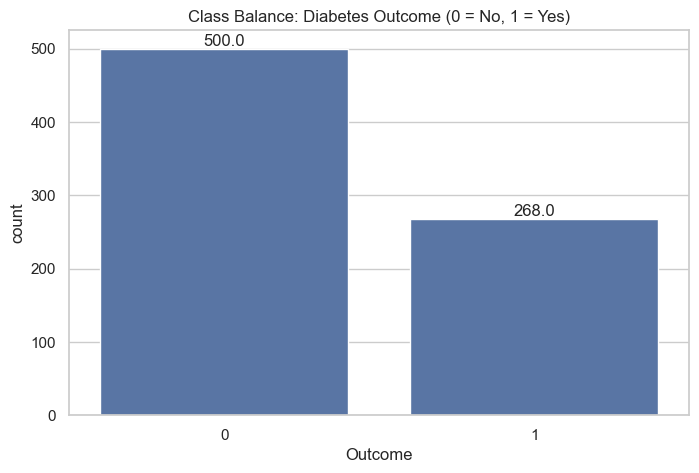

Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64


In [8]:
# A.5 EDA — class balance
ax = sns.countplot(x="Outcome", data=df_a_clean)
ax.set_title("Class Balance: Diabetes Outcome (0 = No, 1 = Yes)")
for p in ax.patches:
    ax.annotate(f"{p.get_height()}", (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.show()

print(df_a_clean["Outcome"].value_counts(normalize=True).rename("proportion"))


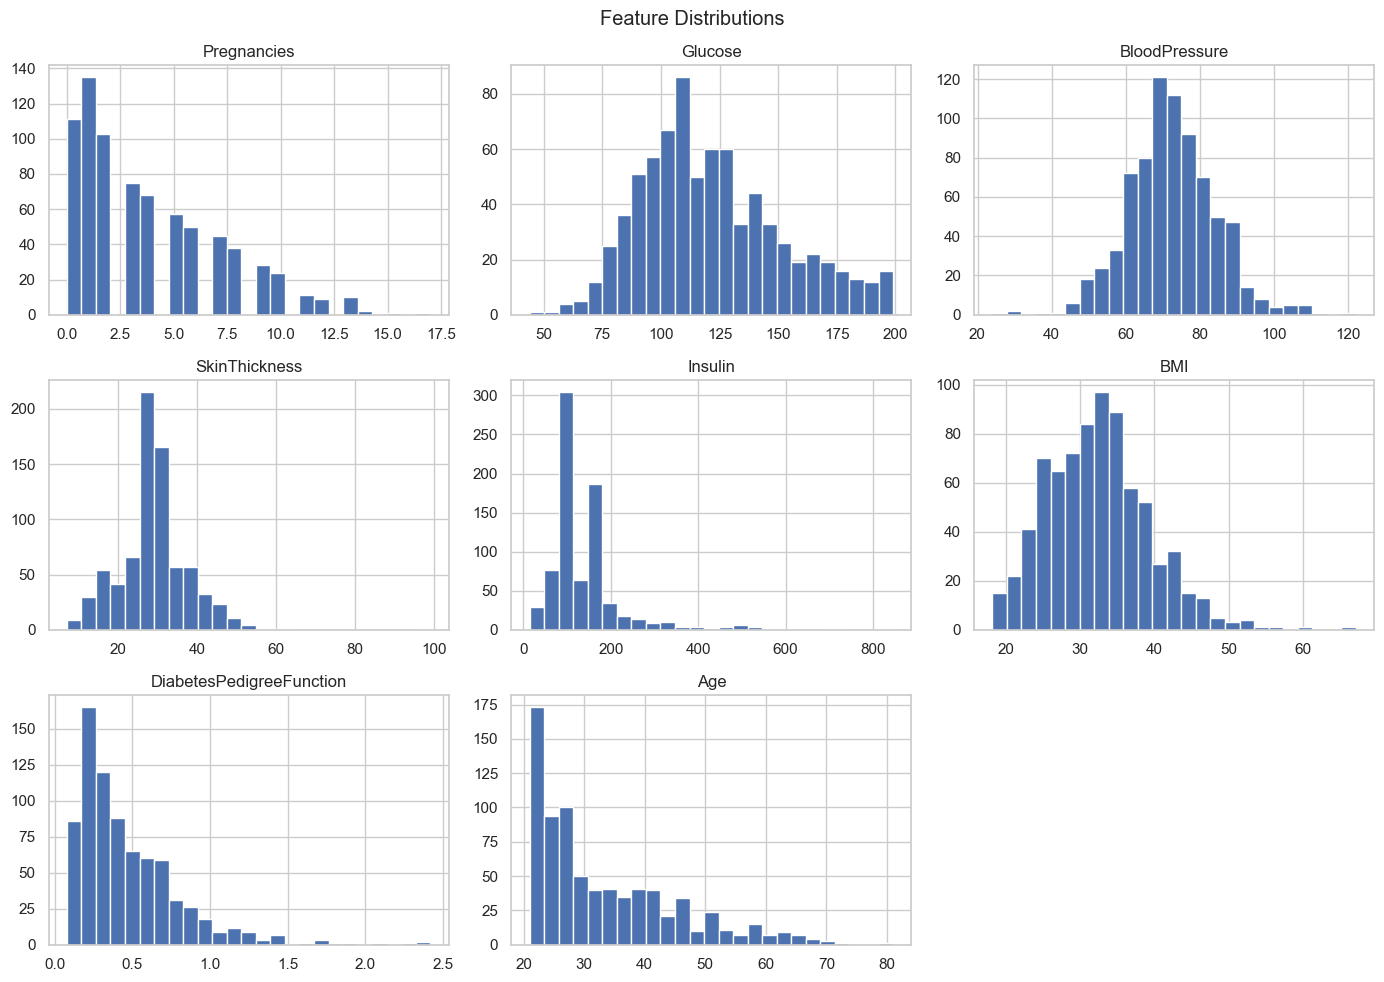

In [9]:
# A.5 EDA — distributions
df_a_clean[numeric_cols_a].hist(figsize=(14, 10), bins=25)
plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.show()


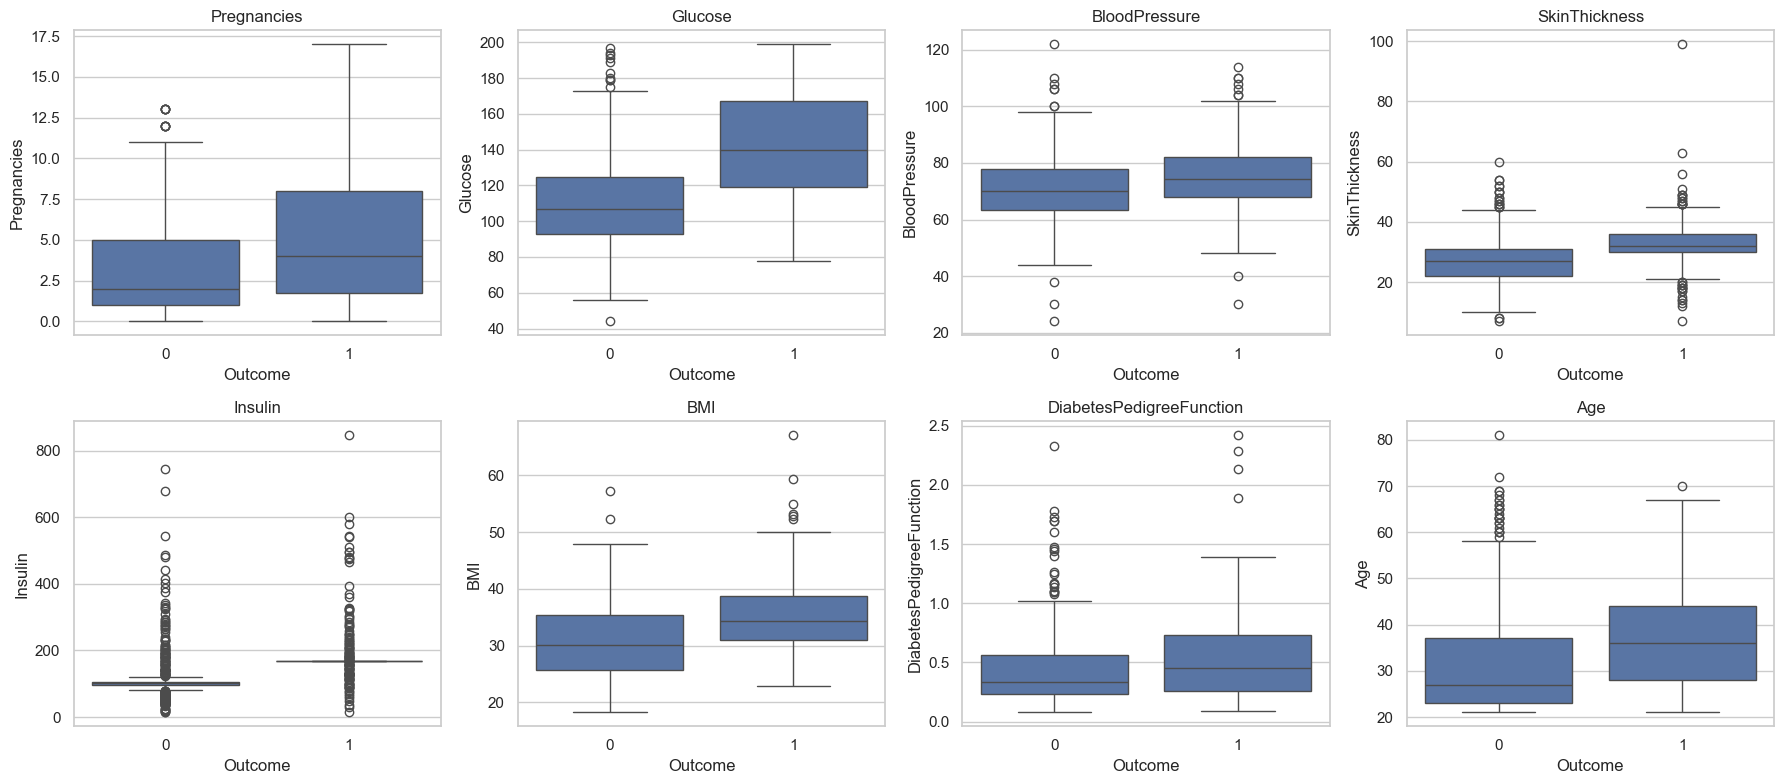

In [10]:
# A.5 EDA — boxplots by outcome (useful to eyeball hypothesis-test candidates)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, numeric_cols_a):
    sns.boxplot(x="Outcome", y=col, data=df_a_clean, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()


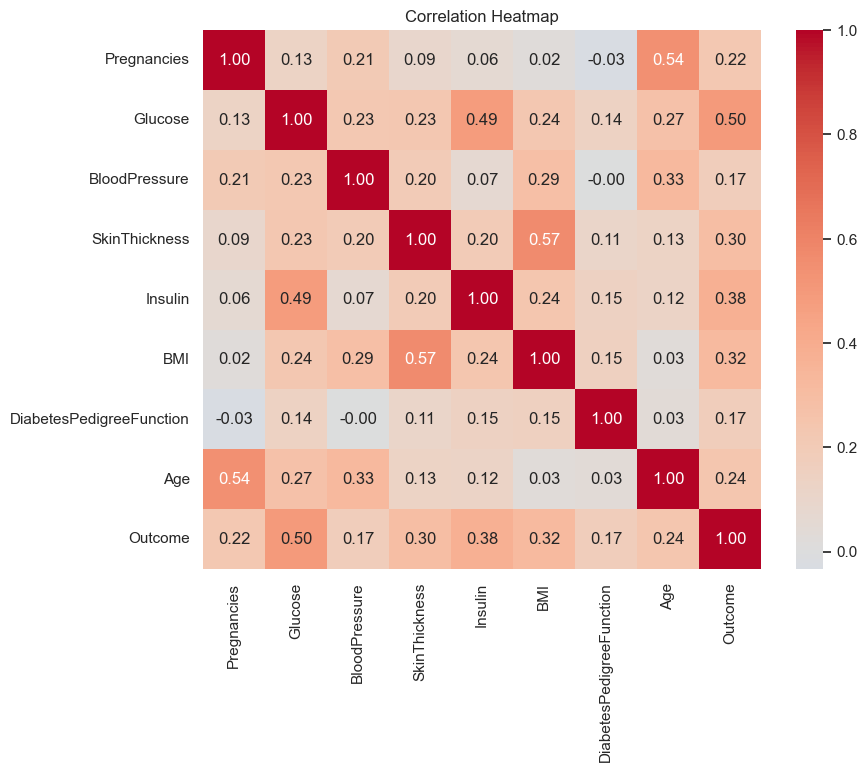

In [11]:
# A.5 EDA — correlation heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(df_a_clean.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()


In [12]:
# A.6 Feature Engineering
df_a_fe = df_a_clean.copy()

df_a_fe["BMI_Category"] = pd.cut(
    df_a_fe["BMI"], bins=[0, 18.5, 25, 30, np.inf],
    labels=["Underweight", "Normal", "Overweight", "Obese"]
)
df_a_fe["Age_Group"] = pd.cut(
    df_a_fe["Age"], bins=[20, 30, 40, 50, 60, np.inf],
    labels=["21-30", "31-40", "41-50", "51-60", "60+"]
)
df_a_fe["Glucose_Insulin_Ratio"] = df_a_fe["Glucose"] / df_a_fe["Insulin"]
df_a_fe["Is_High_BP"] = (df_a_fe["BloodPressure"] > df_a_fe["BloodPressure"].median()).astype(int)

df_a_fe[["BMI", "BMI_Category", "Age", "Age_Group", "Glucose_Insulin_Ratio", "Is_High_BP"]].head()


,BMI,BMI_Category,Age,Age_Group,Glucose_Insulin_Ratio,Is_High_BP
0,33.6,Obese,50,41-50,0.873156,0
1,26.6,Overweight,31,31-40,0.829268,0
2,23.3,Normal,32,31-40,1.079646,0
3,28.1,Overweight,21,21-30,0.946809,0
4,43.1,Obese,33,31-40,0.815476,0


In [13]:
# A.7 Statistical tests

from scipy import stats

# --- (i) Hypothesis Test: independent-samples t-test ---
# H0: mean Glucose is equal between diabetic and non-diabetic patients
group0 = df_a_clean.loc[df_a_clean.Outcome == 0, "Glucose"]
group1 = df_a_clean.loc[df_a_clean.Outcome == 1, "Glucose"]

t_stat, p_val = stats.ttest_ind(group0, group1, equal_var=False)
print(f"[t-test] Glucose ~ Outcome:  t = {t_stat:.3f},  p = {p_val:.2e}")
print("=> Reject H0, means differ significantly" if p_val < 0.05 else "=> Fail to reject H0")


[t-test] Glucose ~ Outcome:  t = -14.992,  p = 8.30e-42
=> Reject H0, means differ significantly


In [14]:
# --- (ii) Chi-square Test of Independence ---
# H0: BMI_Category is independent of diabetes Outcome
contingency = pd.crosstab(df_a_fe["BMI_Category"], df_a_fe["Outcome"])
chi2, p_chi, dof, expected = stats.chi2_contingency(contingency)
print(contingency)
print(f"\n[Chi-square] BMI_Category vs Outcome:  chi2 = {chi2:.3f},  dof = {dof},  p = {p_chi:.2e}")
print("=> Reject H0, BMI category and outcome are associated" if p_chi < 0.05 else "=> Fail to reject H0")


Outcome         0    1
BMI_Category          
Underweight     4    0
Normal        101    7
Overweight    136   44
Obese         259  217

[Chi-square] BMI_Category vs Outcome:  chi2 = 73.133,  dof = 3,  p = 9.10e-16
=> Reject H0, BMI category and outcome are associated


In [15]:
# --- (iii) One-way ANOVA ---
# H0: mean Glucose is equal across all Age_Group buckets
age_groups = [g["Glucose"].values for _, g in df_a_fe.groupby("Age_Group")]
f_stat, p_anova = stats.f_oneway(*age_groups)
print(f"[ANOVA] Glucose ~ Age_Group:  F = {f_stat:.3f},  p = {p_anova:.2e}")
print("=> Reject H0, at least one age group differs" if p_anova < 0.05 else "=> Fail to reject H0")


[ANOVA] Glucose ~ Age_Group:  F = 15.126,  p = 6.60e-12
=> Reject H0, at least one age group differs


In [16]:
# A.8 Feature Selection
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif

X_a = df_a_clean[numeric_cols_a]
y_a = df_a_clean["Outcome"]

# ANOVA F-value based ranking
selector_f = SelectKBest(score_func=f_classif, k="all").fit(X_a, y_a)
f_scores = pd.Series(selector_f.scores_, index=numeric_cols_a).sort_values(ascending=False)

# Mutual information based ranking
mi_scores = pd.Series(
    mutual_info_classif(X_a, y_a, random_state=RANDOM_STATE), index=numeric_cols_a
).sort_values(ascending=False)

pd.DataFrame({"ANOVA_F_score": f_scores, "Mutual_Info": mi_scores}).sort_values(
    "ANOVA_F_score", ascending=False
)


,ANOVA_F_score,Mutual_Info
Glucose,249.923949,0.126140
Insulin,126.971455,0.325872
BMI,84.722280,0.088895
SkinThickness,73.089964,0.152275
Age,46.140611,0.051395
Pregnancies,39.670227,0.060985
BloodPressure,24.048567,0.025256
DiabetesPedigreeFunction,23.871300,0.014590


In [17]:
# A.9 Preprocessing into a model-ready (scaled) tensor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_a, y_a, test_size=0.2, random_state=RANDOM_STATE, stratify=y_a
)

scaler_a = StandardScaler().fit(X_train_a)
X_train_a_scaled = scaler_a.transform(X_train_a)
X_test_a_scaled = scaler_a.transform(X_test_a)

print("Train tensor:", X_train_a_scaled.shape, " Test tensor:", X_test_a_scaled.shape)
print("Mean ~0, Std ~1 check:", X_train_a_scaled.mean().round(3), X_train_a_scaled.std().round(3))


Train tensor: (614, 8)  Test tensor: (154, 8)
Mean ~0, Std ~1 check: -0.0 1.0


---
# Part B — Textual Data: MTSamples Medical Transcriptions

Steps: acquisition & inspection → cleaning (nulls, boilerplate, PHI-pattern removal) → EDA (class distribution, text length, word frequency) → feature engineering (n-grams / TF-IDF) → preprocessing into token sequences.


In [19]:
# B.1 Acquisition & inspection
DATA_DIR_B = "mtsamples.csv"          
CSV_B = "mtsamples.csv"

df_b = pd.read_csv(CSV_B)
print(df_b.shape)
df_b.head()


(4999, 6)


,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."


In [20]:
print(df_b.isnull().sum())
print()
print(f"Number of medical specialties: {df_b['medical_specialty'].nunique()}")
df_b["medical_specialty"].value_counts().head(15)


Unnamed: 0              0
description             0
medical_specialty       0
sample_name             0
transcription          33
keywords             1068
dtype: int64

Number of medical specialties: 40


medical_specialty
Surgery                          1103
Consult - History and Phy.        516
Cardiovascular / Pulmonary        372
Orthopedic                        355
Radiology                         273
General Medicine                  259
Gastroenterology                  230
Neurology                         223
SOAP / Chart / Progress Notes     166
Obstetrics / Gynecology           160
Urology                           158
Discharge Summary                 108
ENT - Otolaryngology               98
Neurosurgery                       94
Hematology - Oncology              90
Name: count, dtype: int64

In [21]:
# B.2 Cleaning
df_b_clean = df_b.copy()

# Drop rows with no transcription text
df_b_clean = df_b_clean.dropna(subset=["transcription"])

# Drop exact duplicate transcriptions
n_dup = df_b_clean.duplicated(subset=["transcription"]).sum()
df_b_clean = df_b_clean.drop_duplicates(subset=["transcription"])
print(f"Dropped {n_dup} duplicate transcriptions -> {df_b_clean.shape[0]} rows remain")


Dropped 2609 duplicate transcriptions -> 2357 rows remain


In [22]:
import re

# PHI-style pattern removal (dates, ID/MRN-like numbers, phone numbers).
# MTSamples is already de-identified with tokens like "XX", "XX/XX/XXXX" — this
# normalizes those + catches any residual identifiers.
def scrub_phi(text: str) -> str:
    text = re.sub(r"\b\d{1,2}/\d{1,2}/\d{2,4}\b", "[DATE]", text)              # dates
    text = re.sub(r"\b\d{3}[-.]?\d{3}[-.]?\d{4}\b", "[PHONE]", text)           # phone numbers
    text = re.sub(r"\bMRN[:#]?\s*\d+\b", "[MRN]", text, flags=re.IGNORECASE)   # medical record numbers
    text = re.sub(r"\bX{2,}\b", "[REDACTED]", text)                            # XX/XXXX placeholders
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_b_clean["transcription_scrubbed"] = df_b_clean["transcription"].astype(str).apply(scrub_phi)
df_b_clean[["transcription", "transcription_scrubbed"]].head(2)


,transcription,transcription_scrubbed
0,"SUBJECTIVE:, This 23-year-old white female pr...","SUBJECTIVE:, This 23-year-old white female pre..."
1,"PAST MEDICAL HISTORY:, He has difficulty climb...","PAST MEDICAL HISTORY:, He has difficulty climb..."


In [23]:
# Remove boilerplate section headers (SUBJECTIVE:, OBJECTIVE:, PLAN:, etc.) and non-alpha noise
boilerplate_pattern = re.compile(
    r"\b(SUBJECTIVE|OBJECTIVE|ASSESSMENT|PLAN|HISTORY OF PRESENT ILLNESS|PHYSICAL EXAMINATION)\s*:",
    flags=re.IGNORECASE
)

def basic_clean(text: str) -> str:
    text = boilerplate_pattern.sub("", text)
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)     # strip digits/punctuation noise
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_b_clean["text_clean"] = df_b_clean["transcription_scrubbed"].apply(basic_clean)
df_b_clean[["transcription_scrubbed", "text_clean"]].head(2)


,transcription_scrubbed,text_clean
0,"SUBJECTIVE:, This 23-year-old white female pre...",this year old white female presents with compl...
1,"PAST MEDICAL HISTORY:, He has difficulty climb...",past medical history he has difficulty climbin...


In [24]:
# B.3 Tokenization, stopword removal, lemmatization
import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def tokenize_and_lemmatize(text: str):
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words and len(t) > 2]
    return tokens

df_b_clean["tokens"] = df_b_clean["text_clean"].apply(tokenize_and_lemmatize)
df_b_clean["text_len_words"] = df_b_clean["tokens"].apply(len)
df_b_clean[["text_clean", "tokens"]].head(2)


,text_clean,tokens
0,this year old white female presents with compl...,"[year, old, white, female, present, complaint,..."
1,past medical history he has difficulty climbin...,"[past, medical, history, difficulty, climbing,..."


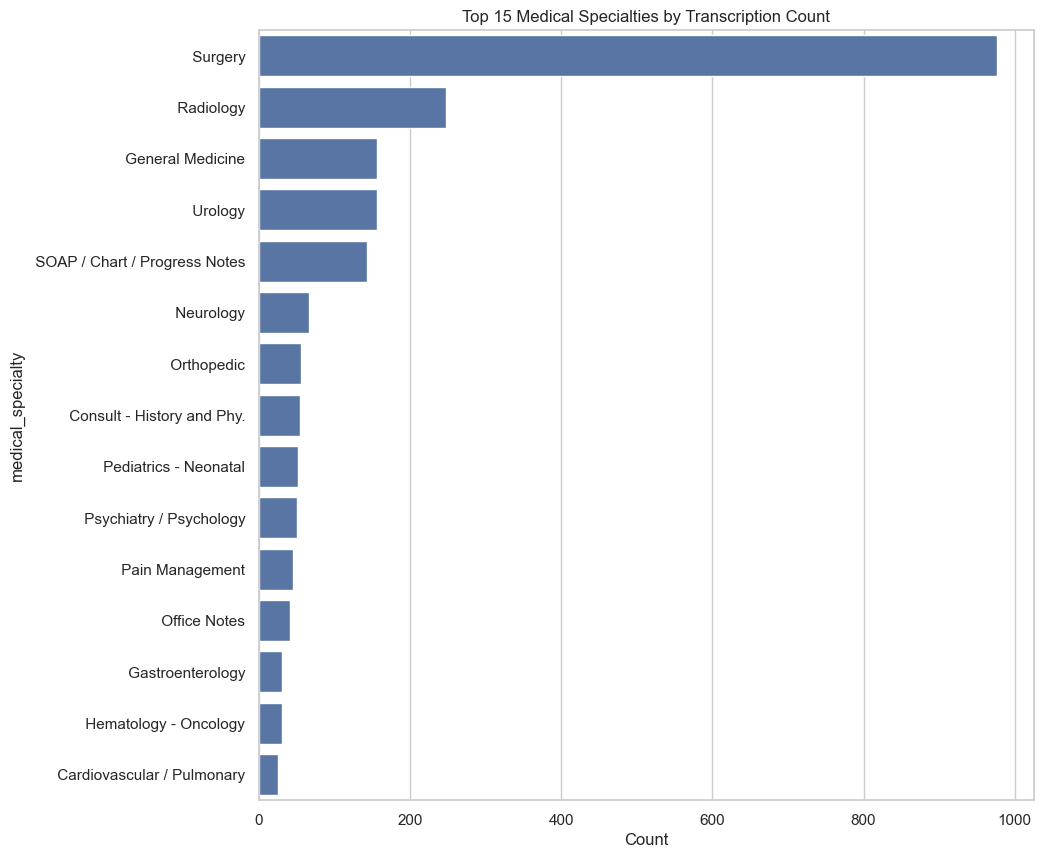

In [25]:
# B.4 EDA
plt.figure(figsize=(10, 10))
top_specialties = df_b_clean["medical_specialty"].value_counts().head(15)
sns.barplot(x=top_specialties.values, y=top_specialties.index)
plt.title("Top 15 Medical Specialties by Transcription Count")
plt.xlabel("Count")
plt.show()


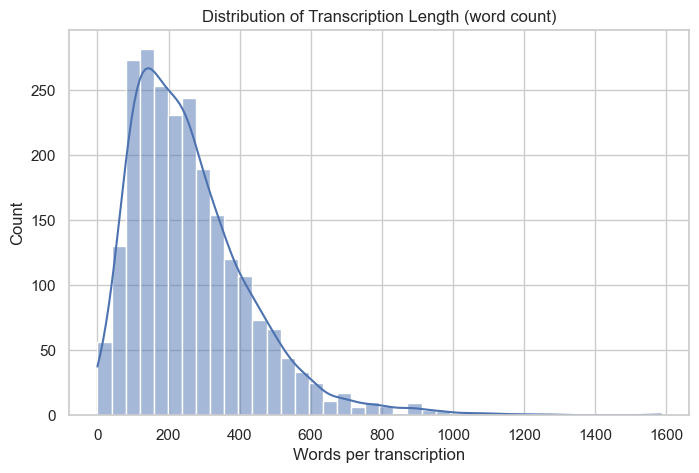

count    2357.000000
mean      261.757743
std       171.170869
min         0.000000
25%       136.000000
50%       229.000000
75%       344.000000
max      1586.000000
Name: text_len_words, dtype: float64


In [26]:
sns.histplot(df_b_clean["text_len_words"], bins=40, kde=True)
plt.title("Distribution of Transcription Length (word count)")
plt.xlabel("Words per transcription")
plt.show()

print(df_b_clean["text_len_words"].describe())


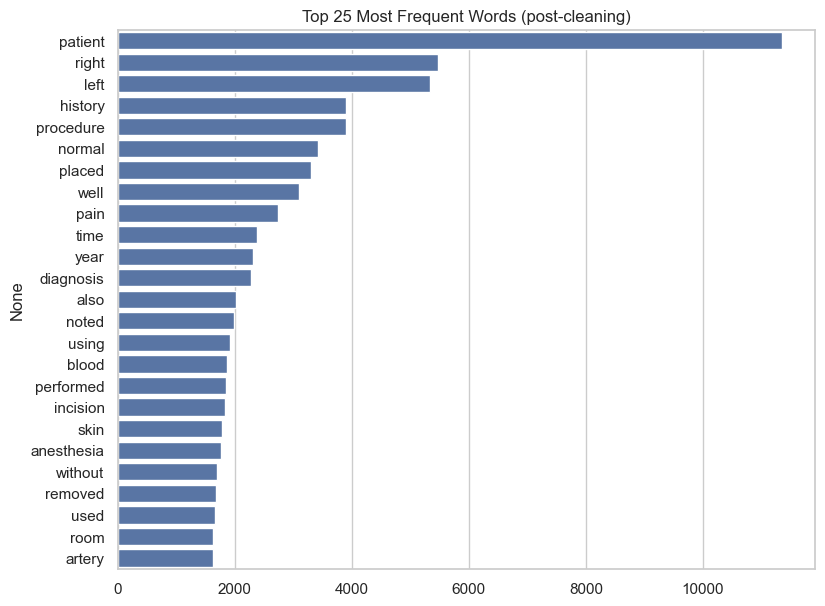

In [27]:
from collections import Counter

all_tokens = [tok for toks in df_b_clean["tokens"] for tok in toks]
freq = Counter(all_tokens)
top_words = pd.Series(dict(freq.most_common(25)))

plt.figure(figsize=(9, 7))
sns.barplot(x=top_words.values, y=top_words.index)
plt.title("Top 25 Most Frequent Words (post-cleaning)")
plt.show()


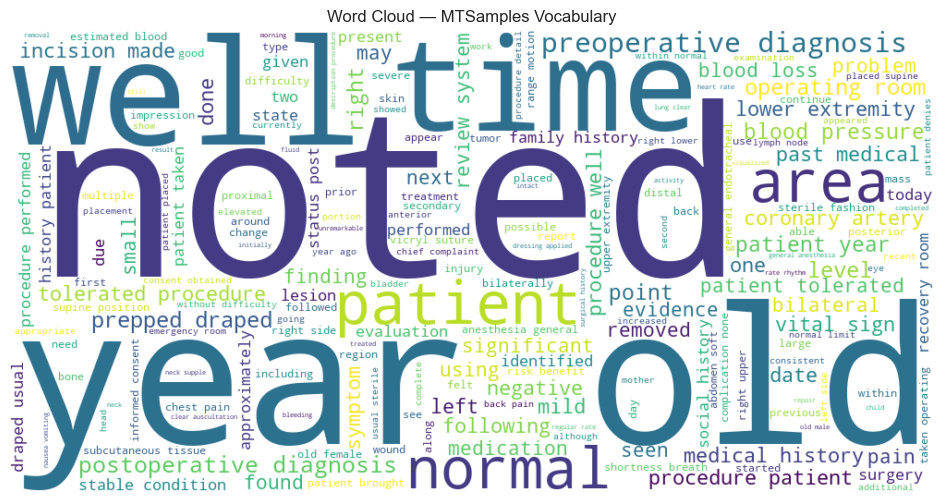

In [29]:
# Word cloud (optional visual EDA)
from wordcloud import WordCloud

wc = WordCloud(width=1000, height=500, background_color="white").generate(" ".join(all_tokens))
plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud — MTSamples Vocabulary")
plt.show()


In [30]:
# B.5 Feature Engineering — TF-IDF (classic model-ready tabular-from-text representation)
from sklearn.feature_extraction.text import TfidfVectorizer

df_b_clean["text_joined"] = df_b_clean["tokens"].apply(lambda t: " ".join(t))

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=3)
X_b_tfidf = tfidf.fit_transform(df_b_clean["text_joined"])
print("TF-IDF matrix shape:", X_b_tfidf.shape)

# Top TF-IDF terms overall, as a quick sanity check
tfidf_sums = pd.Series(np.asarray(X_b_tfidf.sum(axis=0)).ravel(), index=tfidf.get_feature_names_out())
tfidf_sums.sort_values(ascending=False).head(15)


TF-IDF matrix shape: (2357, 5000)


patient      141.325845
right         86.542089
left          83.852581
history       74.080332
procedure     73.963844
normal        67.618677
pain          58.137039
placed        57.683018
well          49.333464
diagnosis     45.099615
time          43.726003
day           41.424190
noted         39.782069
year          39.626588
using         39.187087
dtype: float64

In [31]:
# B.6 Preprocessing into token sequences (model-ready for RNN/Transformer input)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

VOCAB_SIZE = 10000
MAX_LEN = 200

keras_tok = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
keras_tok.fit_on_texts(df_b_clean["text_joined"])

sequences_b = keras_tok.texts_to_sequences(df_b_clean["text_joined"])
X_b_padded = pad_sequences(sequences_b, maxlen=MAX_LEN, padding="post", truncating="post")

print("Padded token-sequence tensor shape:", X_b_padded.shape)
print("Example sequence (first 20 tokens):", X_b_padded[0][:20])


Padded token-sequence tensor shape: (2357, 200)
Example sequence (first 20 tokens): [  12   27  208  132   84  211  121   24  121 4389 8199  694  886   40
 1610 3360 3121 1507  667   11]


---
# Part C — Image Data: Chest X-Ray (Pneumonia) Dataset

Expected folder layout (standard Kaggle download):
```
DATA_DIR_C/
  train/  NORMAL/*.jpeg   PNEUMONIA/*.jpeg
  val/    NORMAL/*.jpeg   PNEUMONIA/*.jpeg
  test/   NORMAL/*.jpeg   PNEUMONIA/*.jpeg
```

Steps: acquisition & inspection → cleaning (corrupt files, metadata anonymization) → EDA → preprocessing (resize/normalize/tensor) → augmentation.


In [32]:
# C.1 Acquisition & inspection
import os
from pathlib import Path

DATA_DIR_C = Path("chest_xray")      

for split in ["train", "val", "test"]:
    for cls in ["NORMAL", "PNEUMONIA"]:
        p = DATA_DIR_C / split / cls
        n = len(list(p.glob("*"))) if p.exists() else 0
        print(f"{split:6s} / {cls:10s}: {n} images")


train  / NORMAL    : 1341 images
train  / PNEUMONIA : 3875 images
val    / NORMAL    : 8 images
val    / PNEUMONIA : 8 images
test   / NORMAL    : 234 images
test   / PNEUMONIA : 390 images


In [33]:
# C.2 Cleaning — verify images aren't corrupt / unreadable
from PIL import Image

def find_corrupt_images(folder: Path):
    bad = []
    for f in folder.rglob("*"):
        if f.is_file():
            try:
                with Image.open(f) as img:
                    img.verify()
            except Exception:
                bad.append(f)
    return bad

corrupt_files = find_corrupt_images(DATA_DIR_C / "train")
print(f"Corrupt/unreadable files found in train/: {len(corrupt_files)}")
for f in corrupt_files:
    print(" -", f)
    # os.remove(f)   # uncomment to actually remove them


Corrupt/unreadable files found in train/: 0


In [34]:
# C.2 Cleaning — imaging metadata anonymization (strip EXIF/DICOM-style tags that could carry PHI)
def strip_exif(src_path: Path, dst_path: Path):
    with Image.open(src_path) as img:
        data = list(img.getdata())
        clean_img = Image.new(img.mode, img.size)
        clean_img.putdata(data)
        dst_path.parent.mkdir(parents=True, exist_ok=True)
        clean_img.save(dst_path)

# Example on one file — scale this loop to the full dataset before training if metadata is a concern
sample_files = list((DATA_DIR_C / "train" / "NORMAL").glob("*"))[:1]
if sample_files:
    out_path = Path("data/chest_xray_clean/train/NORMAL") / sample_files[0].name
    strip_exif(sample_files[0], out_path)
    print("De-identified example saved to:", out_path)


De-identified example saved to: data\chest_xray_clean\train\NORMAL\IM-0115-0001.jpeg


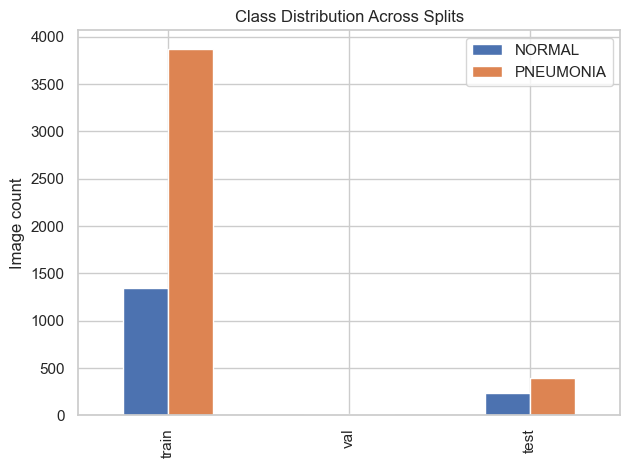

,NORMAL,PNEUMONIA
train,1341,3875
val,8,8
test,234,390


In [35]:
# C.3 EDA — class balance across splits
counts = {}
for split in ["train", "val", "test"]:
    counts[split] = {
        cls: len(list((DATA_DIR_C / split / cls).glob("*")))
        for cls in ["NORMAL", "PNEUMONIA"]
    }
counts_df = pd.DataFrame(counts).T
counts_df.plot(kind="bar", stacked=False, figsize=(7, 5))
plt.title("Class Distribution Across Splits")
plt.ylabel("Image count")
plt.show()
counts_df


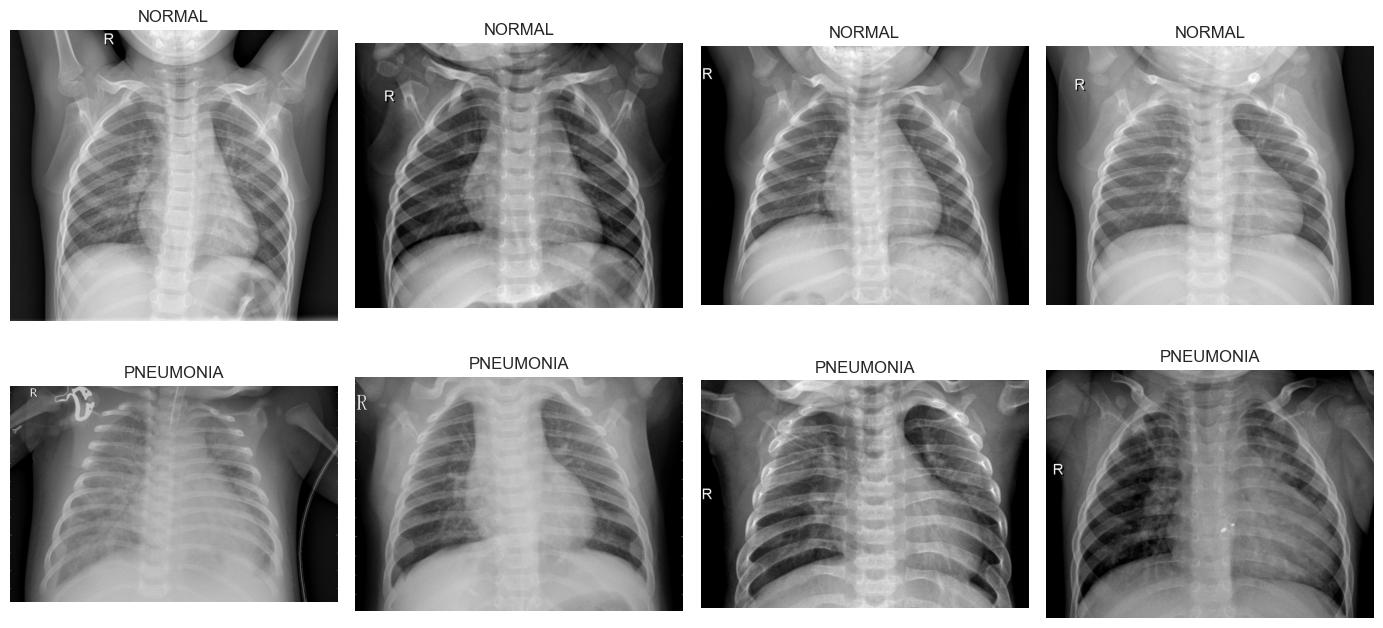

In [36]:
# C.3 EDA — sample images
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, cls in enumerate(["NORMAL", "PNEUMONIA"]):
    files = list((DATA_DIR_C / "train" / cls).glob("*"))[:4]
    for col, f in enumerate(files):
        img = Image.open(f).convert("L")
        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(cls)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()


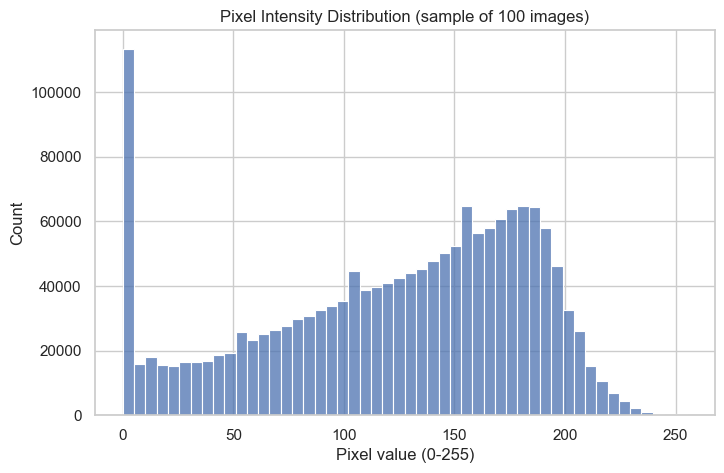

In [37]:
# C.3 EDA — pixel intensity distribution (helps decide normalization strategy)
sample_pixels = []
for cls in ["NORMAL", "PNEUMONIA"]:
    for f in list((DATA_DIR_C / "train" / cls).glob("*"))[:50]:
        img = np.array(Image.open(f).convert("L").resize((128, 128)))
        sample_pixels.append(img.ravel())

sample_pixels = np.concatenate(sample_pixels)
sns.histplot(sample_pixels, bins=50)
plt.title("Pixel Intensity Distribution (sample of 100 images)")
plt.xlabel("Pixel value (0-255)")
plt.show()


In [38]:
# C.4 Preprocessing — resize, normalize, batch into tensors, with on-the-fly augmentation
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (150, 150)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
)
val_test_datagen = ImageDataGenerator(rescale=1.0 / 255)

train_gen = train_datagen.flow_from_directory(
    DATA_DIR_C / "train", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    color_mode="grayscale", class_mode="binary"
)
val_gen = val_test_datagen.flow_from_directory(
    DATA_DIR_C / "val", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    color_mode="grayscale", class_mode="binary"
)
test_gen = val_test_datagen.flow_from_directory(
    DATA_DIR_C / "test", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    color_mode="grayscale", class_mode="binary", shuffle=False
)

xb, yb = next(train_gen)
print("Batch tensor shape:", xb.shape, " labels shape:", yb.shape)
print("Class index mapping:", train_gen.class_indices)


Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Batch tensor shape: (32, 150, 150, 1)  labels shape: (32,)
Class index mapping: {'NORMAL': 0, 'PNEUMONIA': 1}


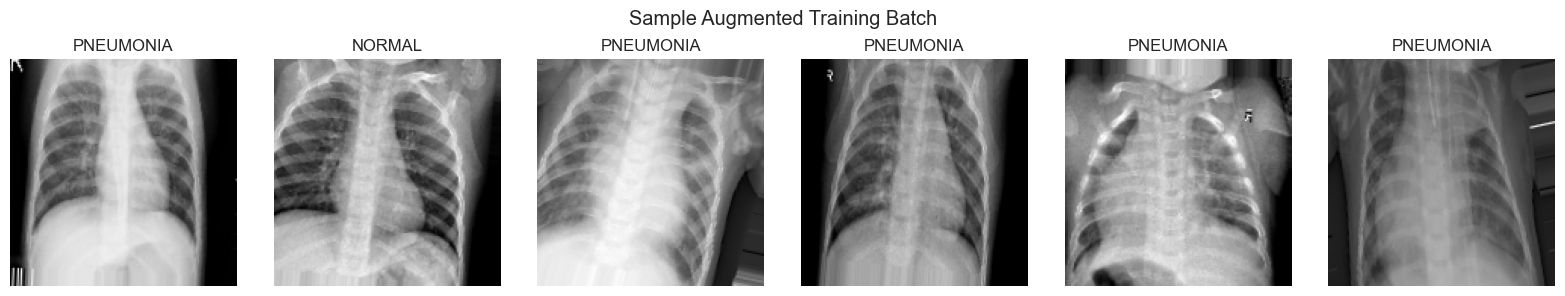

In [39]:
# C.4 Visualize augmented batch
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for i in range(6):
    axes[i].imshow(xb[i].squeeze(), cmap="gray")
    axes[i].set_title("PNEUMONIA" if yb[i] == 1 else "NORMAL")
    axes[i].axis("off")
plt.suptitle("Sample Augmented Training Batch")
plt.tight_layout()
plt.show()


---
# Part D — Signal Data: MIT-BIH Arrhythmia Database (ECG)

Requires the `wfdb` package (`pip install wfdb`) and the MIT-BIH record files (`.dat`, `.hea`, `.atr`) downloaded locally.

Steps: acquisition & inspection → cleaning (baseline wander / powerline noise removal) → EDA → preprocessing (R-peak segmentation into beat windows, normalization) → feature extraction & augmentation.


In [40]:
# D.1 Acquisition & inspection
import wfdb

DATA_DIR_D = "mit-bih-arrhythmia-database-1.0.0"    
RECORD = "100"                # MIT-BIH record number to work with

record = wfdb.rdrecord(f"{DATA_DIR_D}/{RECORD}")
annotation = wfdb.rdann(f"{DATA_DIR_D}/{RECORD}", "atr")

fs = record.fs
signal_raw = record.p_signal[:, 0]   # first channel (e.g. MLII lead)

print("Sampling rate (Hz):", fs)
print("Signal length (samples):", len(signal_raw), " (~%.1f min)" % (len(signal_raw) / fs / 60))
print("Lead names:", record.sig_name)
print("Number of annotated beats:", len(annotation.sample))
print("Beat label distribution:")
print(pd.Series(annotation.symbol).value_counts())


Sampling rate (Hz): 360
Signal length (samples): 650000  (~30.1 min)
Lead names: ['MLII', 'V5']
Number of annotated beats: 2274
Beat label distribution:
N    2239
A      33
+       1
V       1
Name: count, dtype: int64


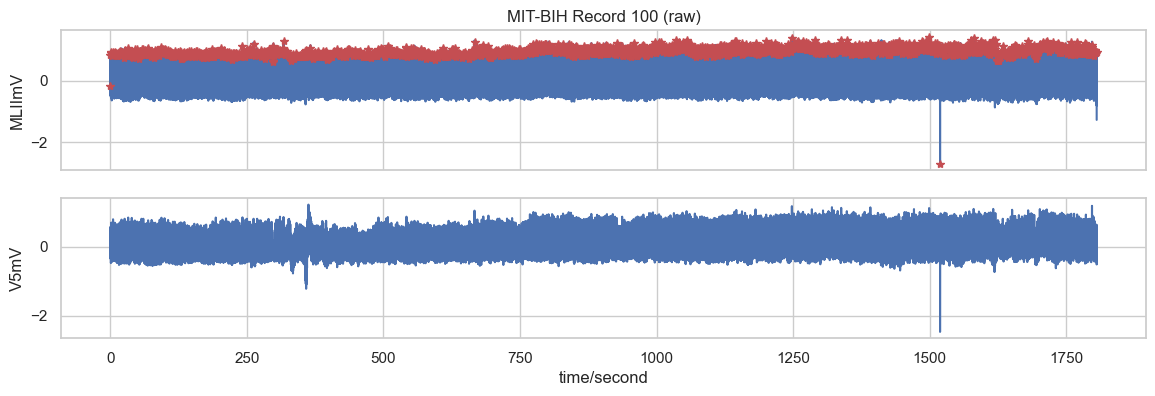

In [41]:
wfdb.plot_wfdb(record=record, annotation=annotation, title=f"MIT-BIH Record {RECORD} (raw)",
               time_units="seconds", figsize=(14, 4))


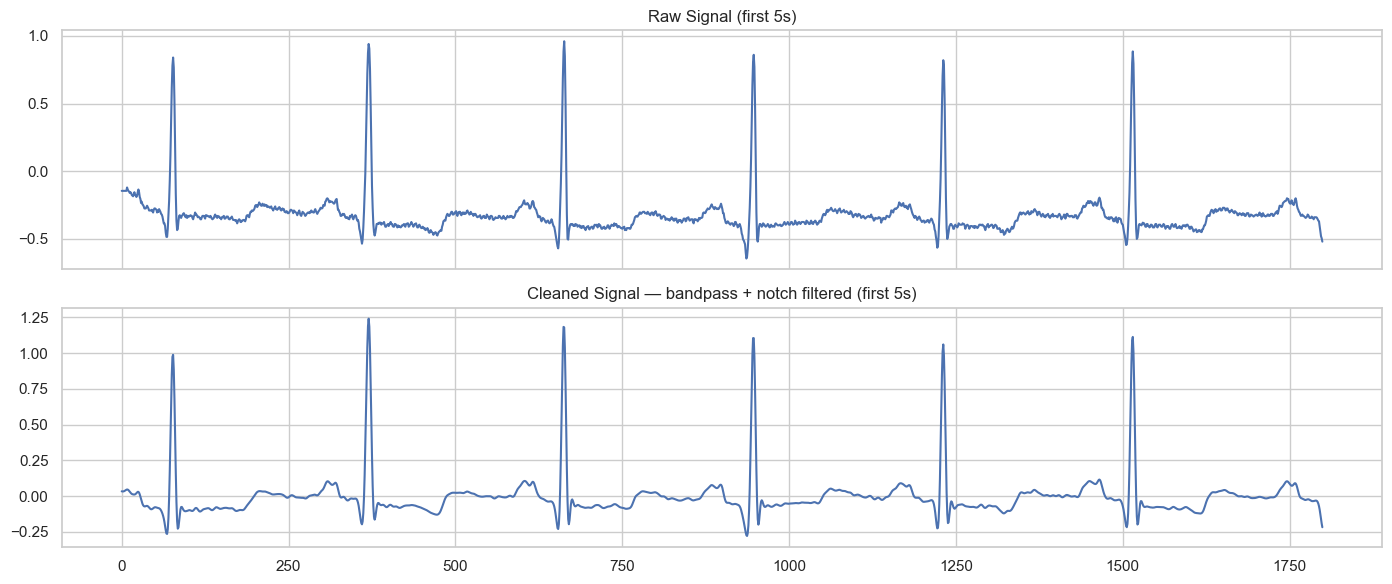

In [42]:
# D.2 Cleaning — remove baseline wander & powerline noise
from scipy.signal import butter, filtfilt, iirnotch

def bandpass_filter(sig, fs, low=0.5, high=40, order=4):
    nyq = 0.5 * fs
    b, a = butter(order, [low / nyq, high / nyq], btype="band")
    return filtfilt(b, a, sig)

def notch_filter(sig, fs, freq=60, quality=30):
    b, a = iirnotch(freq / (fs / 2), quality)
    return filtfilt(b, a, sig)

signal_clean = bandpass_filter(signal_raw, fs)
signal_clean = notch_filter(signal_clean, fs)

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
window = slice(0, fs * 5)   # first 5 seconds
axes[0].plot(signal_raw[window]); axes[0].set_title("Raw Signal (first 5s)")
axes[1].plot(signal_clean[window]); axes[1].set_title("Cleaned Signal — bandpass + notch filtered (first 5s)")
plt.tight_layout()
plt.show()


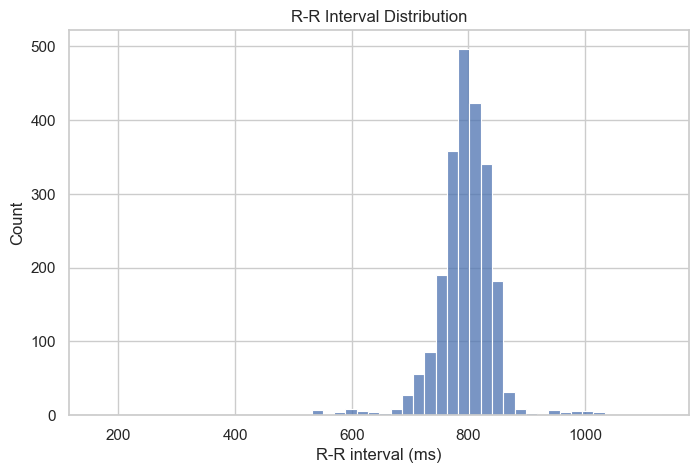

Mean heart rate (bpm): 75.5


In [43]:
# D.3 EDA — beat label distribution & R-R interval analysis
r_peaks = annotation.sample
labels = annotation.symbol

rr_intervals = np.diff(r_peaks) / fs * 1000   # in ms
sns.histplot(rr_intervals, bins=50)
plt.title("R-R Interval Distribution")
plt.xlabel("R-R interval (ms)")
plt.show()

print("Mean heart rate (bpm): %.1f" % (60000 / np.mean(rr_intervals)))


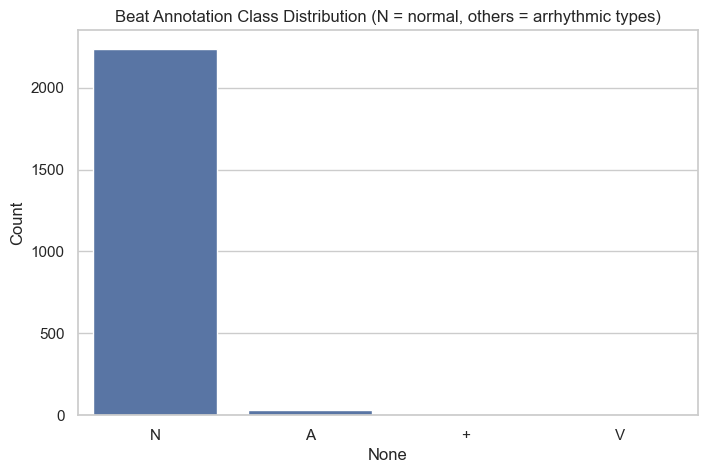

In [44]:
label_counts = pd.Series(labels).value_counts()
sns.barplot(x=label_counts.index, y=label_counts.values)
plt.title("Beat Annotation Class Distribution (N = normal, others = arrhythmic types)")
plt.ylabel("Count")
plt.show()


In [45]:
# D.4 Preprocessing — segment into fixed-width beat windows around each R-peak
WINDOW_SAMPLES = 180   # ~0.5s each side at 360 Hz MIT-BIH sampling rate

def segment_beats(sig, r_peaks, labels, half_window=WINDOW_SAMPLES):
    beats, beat_labels = [], []
    for peak, lab in zip(r_peaks, labels):
        start, end = peak - half_window, peak + half_window
        if start >= 0 and end <= len(sig):
            beats.append(sig[start:end])
            beat_labels.append(lab)
    return np.array(beats), np.array(beat_labels)

beats, beat_labels = segment_beats(signal_clean, r_peaks, labels)
print("Beat window tensor shape:", beats.shape)

# Normalize each beat window (z-score)
beats_norm = (beats - beats.mean(axis=1, keepdims=True)) / (beats.std(axis=1, keepdims=True) + 1e-8)
print("Normalized beat tensor shape:", beats_norm.shape)


Beat window tensor shape: (2271, 360)
Normalized beat tensor shape: (2271, 360)


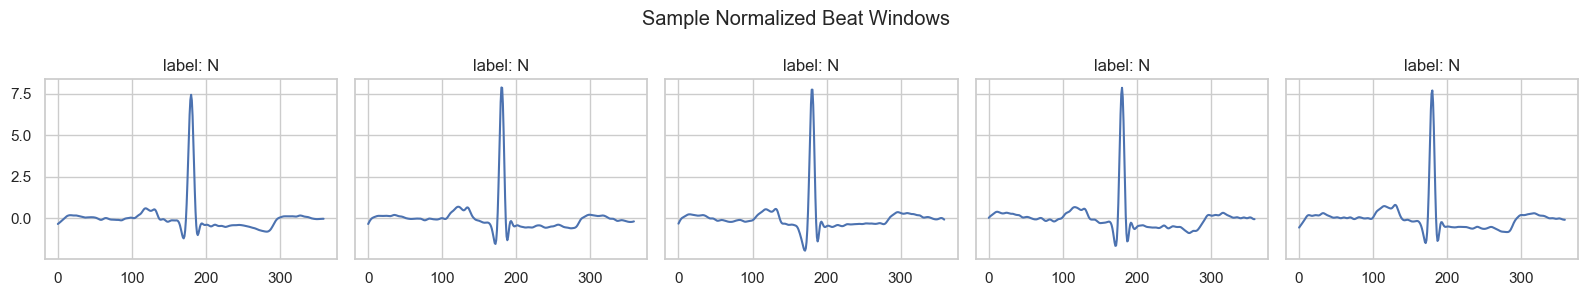

In [46]:
# D.4 Visualize a few normalized beat windows by class
fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharey=True)
for i in range(5):
    axes[i].plot(beats_norm[i])
    axes[i].set_title(f"label: {beat_labels[i]}")
plt.suptitle("Sample Normalized Beat Windows")
plt.tight_layout()
plt.show()


In [47]:
# D.5 Feature extraction — simple statistical + morphological features per beat
from scipy.stats import skew, kurtosis

def extract_beat_features(beat):
    return {
        "mean": beat.mean(),
        "std": beat.std(),
        "skew": skew(beat),
        "kurtosis": kurtosis(beat),
        "max": beat.max(),
        "min": beat.min(),
        "range": beat.max() - beat.min(),
    }

feat_rows = [extract_beat_features(b) for b in beats_norm]
df_d_features = pd.DataFrame(feat_rows)
df_d_features["label"] = beat_labels
df_d_features.head()


,mean,std,skew,kurtosis,max,min,range,label
0,-1.356939e-17,1.0,5.300444,32.028078,7.443347,-1.227239,8.670586,N
1,1.480297e-17,1.0,5.599347,36.849156,7.884291,-1.563354,9.447645,N
2,-9.868649e-18,1.0,5.302919,34.810641,7.753654,-1.968717,9.722371,N
3,0.000000e+00,1.0,5.209744,33.878869,7.865587,-1.681268,9.546855,N
4,9.868649e-18,1.0,5.079550,32.270993,7.703828,-1.511092,9.214920,N


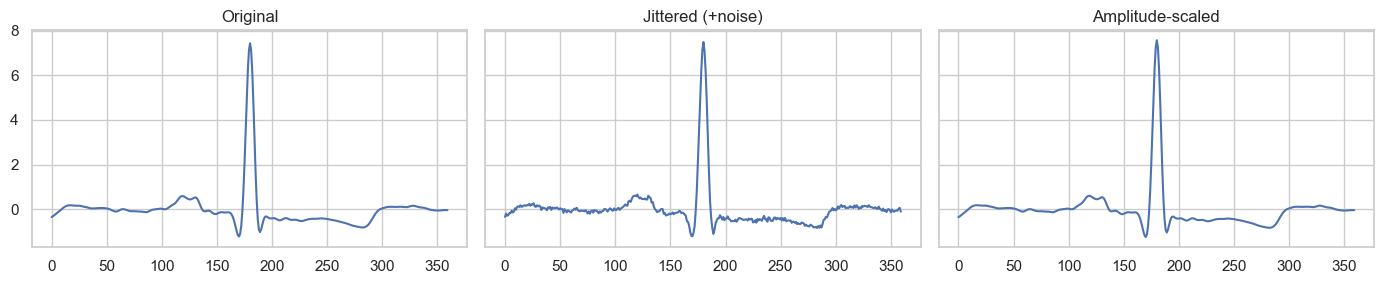

In [48]:
# D.6 Augmentation — jitter (additive noise) & time-warp style scaling, common for ECG data
def augment_jitter(beat, noise_std=0.05):
    return beat + np.random.normal(0, noise_std, size=beat.shape)

def augment_scale(beat, scale_range=(0.9, 1.1)):
    return beat * np.random.uniform(*scale_range)

sample_beat = beats_norm[0]
jittered = augment_jitter(sample_beat)
scaled = augment_scale(sample_beat)

fig, axes = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
axes[0].plot(sample_beat); axes[0].set_title("Original")
axes[1].plot(jittered); axes[1].set_title("Jittered (+noise)")
axes[2].plot(scaled); axes[2].set_title("Amplitude-scaled")
plt.tight_layout()
plt.show()


---
## Summary

| Part | Model-ready output |
|---|---|
| A — Tabular | `X_train_a_scaled`, `X_test_a_scaled` — standardized feature tensors + hypothesis/chi-square/ANOVA results |
| B — Textual | `X_b_tfidf` (TF-IDF matrix) and `X_b_padded` (token-sequence tensor) |
| C — Image | `train_gen` / `val_gen` / `test_gen` — normalized, augmented image batches |
| D — Signal | `beats_norm` (segmented, normalized ECG windows) + `df_d_features` (extracted statistical features) |

**Notes on why each modality needed extra care**, per the lab objective: Part A had missingness encoded as valid-looking zeros; Part B required PHI-pattern scrubbing before any modeling; Part C required corrupt-file checks and metadata anonymization; Part D required explicit noise filtering (baseline wander, powerline interference) before any downstream feature extraction. Adjust `DATA_DIR_*` paths at the top of each part to match your local folder layout, and install any missing packages (`pip install wfdb wordcloud nltk tensorflow scikit-learn`) before running.
